# Structuring Retail Notes: Capital Protection and Reverse Convertibles

**Goal.** Do the structurer's job: break a note into a bond and options, price each
piece, and solve for the headline term the bank can offer (participation rate or coupon)
once fees and the issuer's funding are paid.

**The structurer's equation.** The investor pays 100. The issuer must deliver a package
worth $100 \times (1 - \text{fees})$:

$$\underbrace{100 \times \text{protection} \times P_{issuer}(T)}_{\text{zero-coupon bond}}
  + \underbrace{\text{option package}}_{\text{bought or sold by the investor}} = 100\,(1-\text{fees})$$

where $P_{issuer}(T) = e^{-(r + s)T}$ includes the issuer's credit spread $s$: a note is a
loan to the bank, so a riskier issuer pays more.

**Plan.** 1. Capital-protected note · 2. What drives participation (rates, vol, cap) ·
3. Reverse convertible and barriers · 4. Term sheets.

In [1]:
import os, sys, subprocess
if "google.colab" in sys.modules and not os.path.exists("structuring.py"):
    subprocess.run(["git", "clone", "-q", "https://github.com/adamrejeb86-del/-finance-portfolio.git"], check=True)
    os.chdir("-finance-portfolio/05-structured-notes")

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from structuring import (MarketData, capital_protected_note, reverse_convertible, put, put_european_barrier,
                         put_down_and_in, payoff_capital_protected, payoff_reverse_convertible)

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
NAVY, BORDEAUX, GREY, TEAL = "#1f3b5c", "#7a1f2b", "#8a8a8a", "#2a7f7f"
m = MarketData()
m

MarketData(spot=100.0, rate=0.03, funding_spread=0.01, vol=0.2, div=0.02)

## 1. Capital-protected note (5 years, 100% protection)

The investor gets back at least 100 and participates in the rise of the index.
**Decomposition:** a zero-coupon bond paying 100 at maturity plus at-the-money calls.
Whatever the zero-coupon does not cost is the budget for calls.

In [2]:
cpn = capital_protected_note(m, T=5, protection=1.0, fees=0.02)
decomp = pd.Series({"Investor pays": 100.0, "Fees (2%)": -2.0, "Zero-coupon bond (100 at 5y)": -cpn["zero_coupon"],
                    "Left for options": cpn["option_budget"], "Cost of a 100% ATM call": cpn["option_cost_per_100pct"],
                    "Participation = budget / call cost": cpn["participation"] * 100})
decomp.round(2).to_frame("Per 100 invested")

,Per 100 invested
Investor pays,100.00
Fees (2%),-2.00
Zero-coupon bond (100 at 5y),-81.87
Left for options,16.13
Cost of a 100% ATM call,17.92
Participation = budget / call cost,89.98


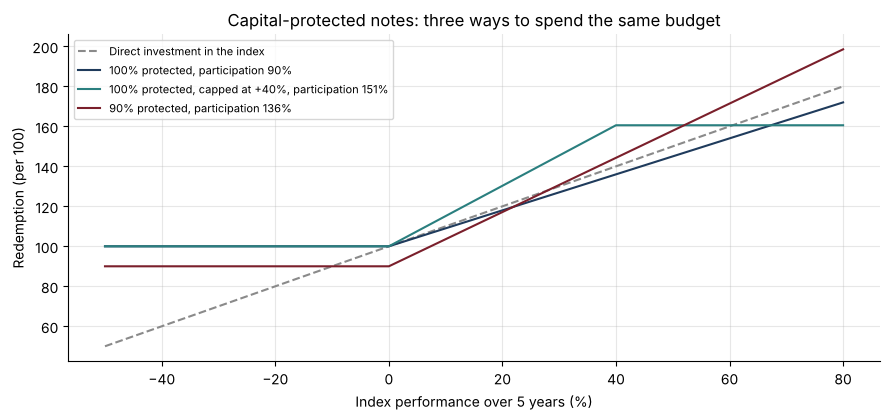

In [3]:
perf = np.linspace(-0.5, 0.8, 300)
capped = capital_protected_note(m, T=5, cap=0.40)
protect90 = capital_protected_note(m, T=5, protection=0.90)
plt.figure(figsize=(9, 4.3))
plt.plot(perf * 100, 100 * (1 + perf), color=GREY, ls="--", label="Direct investment in the index")
plt.plot(perf * 100, payoff_capital_protected(perf, 1.0, cpn["participation"]), color=NAVY,
         label=f"100% protected, participation {cpn['participation']:.0%}")
plt.plot(perf * 100, payoff_capital_protected(perf, 1.0, capped["participation"], cap=0.40), color=TEAL,
         label=f"100% protected, capped at +40%, participation {capped['participation']:.0%}")
plt.plot(perf * 100, payoff_capital_protected(perf, 0.90, protect90["participation"]), color=BORDEAUX,
         label=f"90% protected, participation {protect90['participation']:.0%}")
plt.xlabel("Index performance over 5 years (%)"); plt.ylabel("Redemption (per 100)")
plt.title("Capital-protected notes: three ways to spend the same budget"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig("images/cpn_payoffs.png", dpi=150); plt.show()

Three levers raise the participation: **capping the upside** (the investor sells back a
higher-strike call), **lowering the protection** (a cheaper bond leaves more for options),
or a **higher issuer spread** (a weaker issuer pays more, but carries more credit risk).

## 2. What drives the participation rate

The zero-coupon price is the key. When rates were negative in 2016-2021, the bond cost
more than 100 minus fees and fully protected notes simply could not be built. With rates
back at 3%, they became viable again.

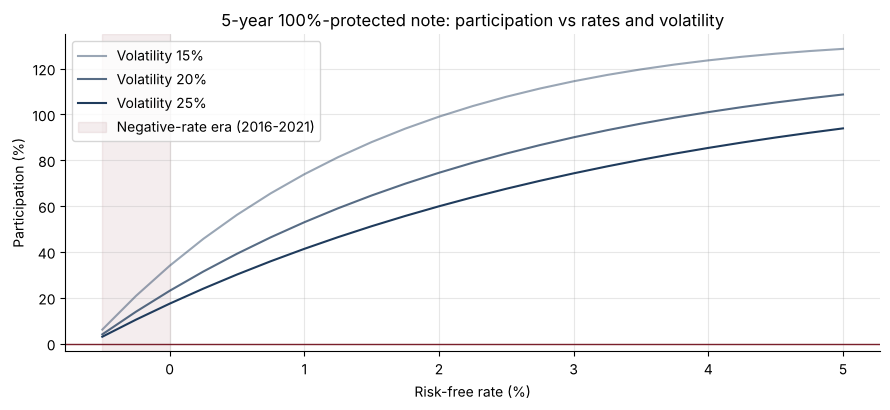

In [4]:
rates = np.linspace(-0.005, 0.05, 23)
vols = [0.15, 0.20, 0.25]
plt.figure(figsize=(9, 4.2))
for v, a in zip(vols, [0.45, 0.75, 1.0]):
    part = [capital_protected_note(replace(m, rate=x, vol=v), T=5)["participation"] for x in rates]
    plt.plot(rates * 100, np.array(part) * 100, color=NAVY, alpha=a, label=f"Volatility {v:.0%}")
plt.axhline(0, color=BORDEAUX, lw=1)
plt.axvspan(-0.5, 0.0, color=BORDEAUX, alpha=0.08, label="Negative-rate era (2016-2021)")
plt.xlabel("Risk-free rate (%)"); plt.ylabel("Participation (%)")
plt.title("5-year 100%-protected note: participation vs rates and volatility"); plt.legend()
plt.tight_layout(); plt.savefig("images/participation_rates.png", dpi=150); plt.show()

Higher volatility makes the calls more expensive, so the participation **falls**: capital
protection sells best when rates are high and volatility is low.

## 3. Reverse convertible (1 year)

The opposite trade: the investor receives a **high fixed coupon** but sells a put to the
issuer. If the stock ends below the threshold, they are repaid in "shares", that is
100 × final level.

| Version | Investor loses capital if... | Put sold |
|---|---|---|
| Plain | $S_T < S_0$ | at-the-money put |
| European barrier 70% | $S_T < 70\%$ (checked at maturity only) | put × 1{S_T < H} |
| American barrier 70% | the stock *ever* trades below 70% and ends below 100% | down-and-in put |

In [5]:
rows = []
for label, kw in [("Plain (no barrier)", {}), ("European barrier 70%", {"barrier": 0.7, "barrier_type": "european"}),
                  ("American barrier 70%", {"barrier": 0.7, "barrier_type": "american"})]:
    rc = reverse_convertible(m, T=1, fees=0.01, **kw)
    rows.append({"Structure": label, "Put sold (per 100)": rc["put_sold"], "Coupon p.a.": rc["coupon_pa"]})
pd.DataFrame(rows).set_index("Structure").style.format({"Put sold (per 100)": "{:.2f}", "Coupon p.a.": "{:.2%}"})

,Put sold (per 100),Coupon p.a.
Structure,,
Plain (no barrier),7.29,10.63%
European barrier 70%,1.42,4.52%
American barrier 70%,2.35,5.49%


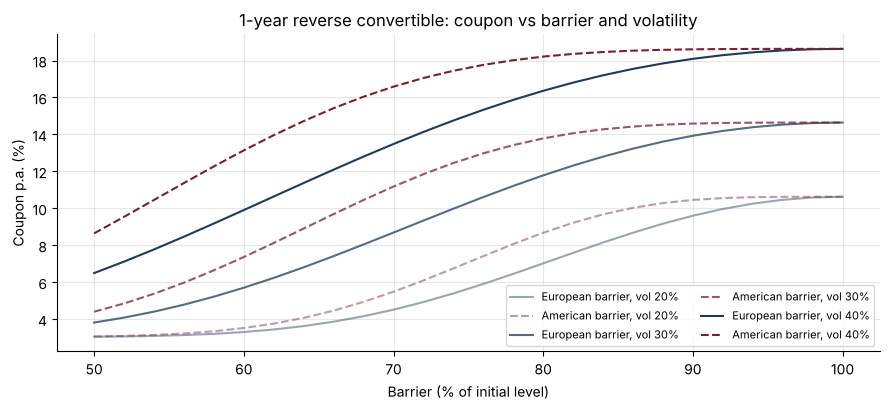

In [6]:
barriers = np.linspace(0.5, 1.0, 26)
plt.figure(figsize=(9, 4.2))
for v, a in zip([0.20, 0.30, 0.40], [0.45, 0.75, 1.0]):
    mv = replace(m, vol=v)
    plt.plot(barriers * 100, [reverse_convertible(mv, barrier=b)["coupon_pa"] * 100 for b in barriers],
             color=NAVY, alpha=a, label=f"European barrier, vol {v:.0%}")
    plt.plot(barriers * 100, [reverse_convertible(mv, barrier=b, barrier_type="american")["coupon_pa"] * 100 for b in barriers],
             color=BORDEAUX, alpha=a, ls="--", label=f"American barrier, vol {v:.0%}")
plt.xlabel("Barrier (% of initial level)"); plt.ylabel("Coupon p.a. (%)")
plt.title("1-year reverse convertible: coupon vs barrier and volatility"); plt.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.savefig("images/rc_coupons.png", dpi=150); plt.show()

**Reading the chart.** The investor is paid for the risk they sell: a higher barrier or a
more volatile stock means a more valuable put and therefore a bigger coupon. An American
barrier is breached more often than a European one, so it pays more for the same level.
This is the trade-off a salesperson has to explain to the client.

## 4. Scenario table and term sheets

In [7]:
rc = reverse_convertible(m, T=1, barrier=0.7)
finals = np.array([0.5, 0.65, 0.7, 0.85, 1.0, 1.2])
scen = pd.DataFrame({"Stock at maturity": finals,
                     "Reverse convertible (Eur. 70%)": payoff_reverse_convertible(finals, rc["coupon_pa"], barrier=0.7),
                     "Direct holding of the stock": 100 * finals + 100 * (np.exp(m.div) - 1)})
scen.style.format({"Stock at maturity": "{:.0%}", "Reverse convertible (Eur. 70%)": "{:.1f}",
                   "Direct holding of the stock": "{:.1f}"})

,Stock at maturity,Reverse convertible (Eur. 70%),Direct holding of the stock
0,50%,54.5,52.0
1,65%,69.5,67.0
2,70%,104.5,72.0
3,85%,104.5,87.0
4,100%,104.5,102.0
5,120%,104.5,122.0


In [8]:
def term_sheet(name, maturity, terms):
    rows = [("Product", name), ("Issuer funding", f"risk-free {m.rate:.1%} + spread {m.funding_spread:.1%}"),
            ("Maturity", f"{maturity} years"), *terms]
    return pd.DataFrame(rows, columns=["Feature", "Term"]).set_index("Feature")

display(term_sheet("Capital-protected note on index", 5,
                   [("Protection", "100% at maturity"), ("Participation", f"{cpn['participation']:.0%} of the index rise"),
                    ("Fees", "2%")]))
display(term_sheet("Reverse convertible, European barrier", 1,
                   [("Coupon", f"{rc['coupon_pa']:.2%} p.a., paid whatever happens"),
                    ("Capital", "100% if the stock ends above 70%, otherwise final level"), ("Fees", "1%")]))

,Term
Feature,
Product,Capital-protected note on index
Issuer funding,risk-free 3.0% + spread 1.0%
Maturity,5 years
Protection,100% at maturity
Participation,90% of the index rise
Fees,2%


,Term
Feature,
Product,"Reverse convertible, European barrier"
Issuer funding,risk-free 3.0% + spread 1.0%
Maturity,1 years
Coupon,"4.52% p.a., paid whatever happens"
Capital,"100% if the stock ends above 70%, otherwise fi..."
Fees,1%


## Conclusions
- Every note is a bond plus options; the budget identity is checked in `test_structuring.py`.
- Capital protection depends on rates: impossible with negative rates, about 90%
  participation over 5 years at 3% rates and 20% volatility.
- Reverse convertibles monetise volatility: the coupon is the price of the put the client sells.
- **Next steps:** price these notes with the volatility smile (project 03), add the
  issuer's callable features, and autocallable structures (project 02).